In [1]:
import os
from dotenv import load_dotenv
from tavily import TavilyClient
from typing import Literal
from langchain_openai import ChatOpenAI

# .env dosyasını yükle
load_dotenv()

# Tavily Client
tavily_client = TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))

def web_search(
    query: str,
    max_results: int = 5,
    topic: Literal["general", "sports", "news", "finance"] = "general",
    include_raw_content: bool = False
):
    """Run a web search"""
    return tavily_client.search(
        query,
        max_results=max_results,
        include_raw_content=include_raw_content,
        topic=topic
    )

# OpenRouter üzerinden ChatOpenAI kullanımı
model = ChatOpenAI(
    model="nvidia/nemotron-3-ultra-550b-a55b:free",
    api_key=os.getenv("OPENROUTER_API_KEY"),
    base_url="https://openrouter.ai/api/v1"
)

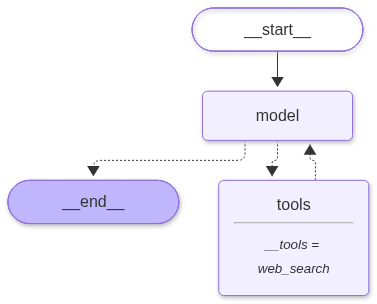

In [2]:
from langchain.agents import create_agent


simple_agent=create_agent(
    model=model,
    tools=[web_search]
)
simple_agent

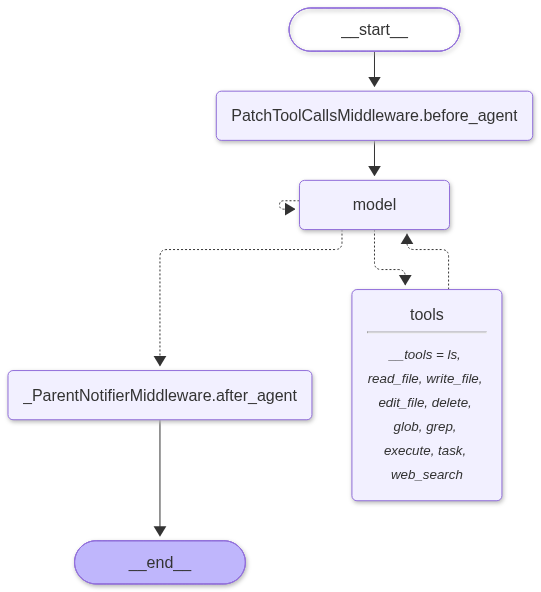

In [3]:
## agent

from deepagents import create_deep_agent

deepagent=create_deep_agent(
    model=model,
    tools=[web_search],
    system_prompt="Act as a researcher"
)
deepagent

In [4]:
result = deepagent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
result

{'messages': [HumanMessage(content='What is deepagent?', additional_kwargs={}, response_metadata={}, id='a1dcdb06-8e7a-4830-bc96-51a0af06201e'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 67, 'prompt_tokens': 3067, 'total_tokens': 3134, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': 0, 'reasoning_tokens': 28, 'rejected_prediction_tokens': None, 'text_tokens': None, 'image_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None, 'video_tokens': 0}, 'cost': 0, 'is_byok': False, 'cost_details': {'upstream_inference_cost': 0, 'upstream_inference_prompt_cost': 0, 'upstream_inference_completions_cost': 0}}, 'model_provider': 'openai', 'model_name': 'nvidia/nemotron-3-ultra-550b-a55b:free', 'system_fingerprint': None, 'id': 'gen-1794248652-ghzJs3vDhu0LPmiTe0FX', 'finish_reason': 'tool_calls', 'logp

In [5]:
result["messages"][-1].content

'Based on my research, **"DeepAgent" refers to three distinct things** — a common name used by different projects/companies. Here\'s a breakdown:\n\n---\n\n## 1. **LangChain\'s Deep Agents (deepagents)** — *Agent Framework/Harness*\n- **What:** An open-source **agent harness** built on **LangGraph** by LangChain.\n- **Purpose:** Build **complex, multi-step, long-running AI agents** with:\n  - **Planning** (task decomposition, progress tracking, adaptation)\n  - **Virtual filesystem** for context management & long-term memory\n  - **Sub-agent spawning** (parallel delegation with isolated context)\n  - **Skills system** (reusable prompt + tool bundles)\n  - **Human-in-the-loop** support\n- **Install:** `pip install deepagents` / `uv add deepagents`\n- **Repo:** `github.com/langchain-ai/deepagents` (30k+ stars)\n- **Docs:** `docs.langchain.com/oss/python/deepagents/overview`\n- **Use when:** You need a batteries-included, production-ready agent for research, coding, or multi-step workflow